<a href="https://colab.research.google.com/github/abdumalikov443/computer_vision/blob/main/menu_detector_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
print('Menu Detector')

Menu Detector


In [28]:
# -------------------------
# import libraries
# -------------------------

from google.colab import drive
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2

from PIL import Image, UnidentifiedImageError # python image library
from torch.utils.data import Dataset, DataLoader
import os
import numpy as np

In [29]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
# Define dataset path

DATASET_PATH = '/content/drive/MyDrive/food101_dataset'
print("Dataset path: ", DATASET_PATH)

CUSTOM_CLASS_MAPPING = {
    'hot_dog': 'hot_dog',
    'kebab': 'kebab',
    'pilaf': 'pilaf',
    'pancakes': 'dessert', # label grouping | class consolidation
    'chocolate_cake': 'dessert',
    'pizza': 'pizza',
    'hamburger': 'hamburger'
}

CLASSES = ['hot_dog', 'kebab', 'pilaf', 'pizza', 'dessert', 'hamburger']
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}  # class larni raqamlarga almashtirib / biriktirb beradi
NUM_CLASSES = len(CLASSES)

print(NUM_CLASSES)
print("Class to index: ", CLASS_TO_IDX)

# Compose => bu step by step ishlarni bajarish uchun
# resize => rasmni bir hil korinishga keltirish
# tensor => raqamlarga ogiramiz
# 0.0 - 1.0 float, oldin H, W, C => C, H, W | Red, Green, Blue
# Normalize => chanellarni togirlab beradi normalize qiladi
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225])
])

Dataset path:  /content/drive/MyDrive/food101_dataset
6
Class to index:  {'hot_dog': 0, 'kebab': 1, 'pilaf': 2, 'pizza': 3, 'dessert': 4, 'hamburger': 5}


In [31]:
# ------------------
# Custom Dataset Class
# ------------------  koprik image fileni AI modelga uzatish uchun

class FoodDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        # print('images_length', len(self.images))  # filelar length uchun data hajmi
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        # print('image_path', img_path)
        label = self.labels[idx]
        # print('label', label)
        try:
            image = Image.open(img_path).convert('RGB') # 3 Channel
        except (UnidentifiedImageError, OSError):
            print(f"Skipping broken image: {img_path}")
            return self.__getitem__((idx + 1) % len(self.images))
        if self.transform:
            image = self.transform(image)
        return image, label

In [32]:
# ------------------
# Gather and Split Data   [ umumiy hamma data ni split qilib ajratib chiqamiz ]
# ------------------

all_images = []
for original_class, mapped_class in CUSTOM_CLASS_MAPPING.items():
    class_path = os.path.join(DATASET_PATH, original_class)
    print('class_path:', class_path)
    if not os.path.exists(class_path):
        print(f"Warning: {class_path} not found")
        continue
    for img in os.listdir(class_path):
        if img.endswith(('.jpg', '.jpeg', '.png')):
            full_path = os.path.join(class_path, img)
            all_images.append((full_path, CLASS_TO_IDX[mapped_class]))

np.random.shuffle(all_images) # dataset random
split = int(0.8 * len(all_images))
train_data = all_images[:split]  # 1000 | 800 train_data | 200 val_data
val_data = all_images[split:]

train_images, train_labels = zip(*train_data)
val_images, val_labels = zip(*val_data)

print('all_images:', all_images)

dataset = FoodDataset(train_images, train_labels)
print(len(dataset))
img, lbl = dataset[0]

class_path: /content/drive/MyDrive/food101_dataset/hot_dog
class_path: /content/drive/MyDrive/food101_dataset/kebab
class_path: /content/drive/MyDrive/food101_dataset/pilaf
class_path: /content/drive/MyDrive/food101_dataset/pancakes
class_path: /content/drive/MyDrive/food101_dataset/chocolate_cake
class_path: /content/drive/MyDrive/food101_dataset/pizza
class_path: /content/drive/MyDrive/food101_dataset/hamburger
all_images: [('/content/drive/MyDrive/food101_dataset/pizza/2247711.jpg', 3), ('/content/drive/MyDrive/food101_dataset/hot_dog/124323.jpg', 0), ('/content/drive/MyDrive/food101_dataset/pizza/771878.jpg', 3), ('/content/drive/MyDrive/food101_dataset/hamburger/2894838.jpg', 5), ('/content/drive/MyDrive/food101_dataset/hot_dog/1210977.jpg', 0), ('/content/drive/MyDrive/food101_dataset/pizza/430118.jpg', 3), ('/content/drive/MyDrive/food101_dataset/pizza/476421.jpg', 3), ('/content/drive/MyDrive/food101_dataset/hamburger/2634081.jpg', 5), ('/content/drive/MyDrive/food101_dataset/h

In [33]:
train_dataset = FoodDataset(train_images, train_labels, transform=transform)
val_dataset = FoodDataset(val_images, val_labels, transform=transform)

In [34]:
# train jarayonida ketma ketlik
# batch size => birdaniga 32ta rasmni organadi
# shuffle => modeldan rasimlarni ketmaketligin yodlab olishni inkor qiladi
# num_workers => backgrounda ikita ishchi
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

images_length 4048
images_length 4048


In [35]:
# pretrained model | lightweight | CNN
# IMAGENET => train bolgan model 1000ta class mavjud shuncha ovqatni taniy oladi
model = mobilenet_v2(weights="IMAGENET1K_V1")

# fine-tuning => mobilent hamma feature ishlatamiz ohiriga ozimizni classni qoshamiz
# backbone => mobile net miyyasini ishlatib fine-tune qilamiz
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)

In [36]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device', device)
model = model.to(device)

device cuda


In [37]:
criterion = nn.CrossEntropyLoss() # Loss Function => multi class slassification bu yerda model predict qilayotkanda bir biriga taqqosalb chiqadi
optimizer = optim.Adam(model.parameters(), lr=0.001) # Optimizer weight => parametrlarni update qlib beradi
torch.backends.cudnn.benchmark = True # bechmark Setting | trick bu model aynan gpu bilan ishlashda eng tez algorithmdi topib tezlashtirib

In [38]:
# --------------------
# Training Loop
# --------------------

NUM_EPOCHS = 10  # AI MODEL 10 martda datasetni aylanadi train
best_accuracy = 0.0  # eng zor natijani save qilish uchun

for epoch in range(NUM_EPOCHS):
    model.train()  # train mode yoqtik
    running_loss = 0.0  # yoqotishlar 70% natija bor, 30% loss korsatadi

    for images, labels in train_loader:  # forward and backward(back propagation)
        # 1 martda train qilish jarayon forward
        # 2 martda ortga qaytish backward
        images, labels = images.to(device), labels.to(device)  # convert to gpu
        optimizer.zero_grad()  # zero the gradient katta raqamlarni nolga tushurish
        outputs = model(images)  # Forward Pass | Cnn ga image jonatadi layerla orqali tanib oladi
        # 5ta classdan kelgan outputni taminlaydi

        loss = criterion(outputs, labels)  # Calculate loss notogri va togri javobdagi tafovut
        loss.backward()  # backpropagation amalga oshadi
        optimizer.step()  # weight => har safar ozgaradi # Adam optimizer
        running_loss += loss.item()  # Track loss

    # Validation => iteration dan keyin traindi tekshiramiz
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_acc = 100 * correct / total  # Calculate Validation Accuracy
    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] Loss: {running_loss/len(train_loader):.4f}, Val Accuracy: {val_acc:.2f}%")

    if val_acc > best_accuracy:
        best_accuracy = val_acc
        torch.save(model.state_dict(), '/content/menu_detector.pth')
        print("Saved new best model!")

images_length 4048
images_length 4048
images_length 4048
images_length 1013
images_length 4048
Epoch [1/10] Loss: 0.5784, Val Accuracy: 87.46%
Saved new best model!
images_length 4048
images_length 4048
images_length 4048
images_length 1013
images_length 4048
Epoch [2/10] Loss: 0.3622, Val Accuracy: 86.28%
images_length 4048
images_length 4048
images_length 4048
images_length 1013
images_length 4048
Epoch [3/10] Loss: 0.3138, Val Accuracy: 89.04%
Saved new best model!
images_length 4048
images_length 4048
images_length 4048
images_length 1013
images_length 4048
Epoch [4/10] Loss: 0.2572, Val Accuracy: 81.93%
images_length 4048
images_length 4048
images_length 4048
images_length 1013
images_length 4048
Epoch [5/10] Loss: 0.1697, Val Accuracy: 88.85%
images_length 4048
images_length 4048
images_length 4048
images_length 1013
images_length 4048
Epoch [6/10] Loss: 0.1838, Val Accuracy: 86.08%
images_length 4048
images_length 4048
images_length 4048
images_length 1013
images_length 4048
Epo

# **menu_detector** model usage

device: cuda
Upload one or more images of hamburger or hot dog:


Saving 3638819.jpg to 3638819.jpg


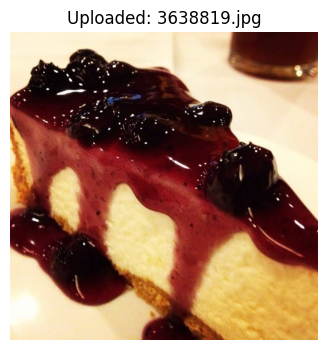

Prediction:
  dessert: 100.00%
  hamburger: 0.00%
  pizza: 0.00%
  hot_dog: 0.00%


In [41]:
# ------------------
# Required Imports
# ------------------

import torch
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2
from PIL import Image
from google.colab import files
import io
import matplotlib.pyplot as plt

# ------------------
# Define Semantic Classes
# ------------------

CLASSES = ['hot_dog', 'kebab', 'pilaf', 'pizza', 'dessert', 'hamburger']
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}

# ------------------
# Transform for Uploaded Images (no augmentations!)
# ------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# ------------------
# Load Model
# ------------------
model = mobilenet_v2(weights=None)
model.classifier[1] = torch.nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model.load_state_dict(torch.load('/content/menu_detector.pth', map_location='cpu'))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
model = model.to(device)
model.eval()

# ------------------
# Upload & Predict
# ------------------
print("Upload one or more images of hamburger or hot dog:")
uploaded = files.upload()

for image_name in uploaded.keys():
    image = Image.open(io.BytesIO(uploaded[image_name])).convert('RGB')

    # Display image
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f'Uploaded: {image_name}')
    plt.show()

    # Predict
    image_tensor = transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(image_tensor)
        probs = torch.softmax(output, dim=1)[0]
        topk = torch.topk(probs, 4)

    print("Prediction:")
    for i in range(topk.indices.size(0)):
        label = CLASSES[topk.indices[i]]
        confidence = topk.values[i].item() * 100
        print(f"  {label}: {confidence:.2f}%")